# How sure are we that each mtDSB mouse did or did not respond?

So far each mtDSB mouse is called responder or non-responder by a hard rule (whole-section OL ISR score above the
highest control, `utils.ol_response.responder_calls`). With three controls per slide, the "control range" is itself
uncertain, so a yes / no call overstates what we know. Here each mouse instead gets a **posterior probability of
responding**, from a two-component Bayesian mixture anchored on the controls (`utils/responder_mixture.py`):

* readouts centred on the mean of the controls of the same Xenium slide (slide = age cohort);
* non-responders are drawn like controls: multivariate t with the pooled control (co)variance, df = 6 controls minus
  2 slides, widened for the uncertainty in the slide mean;
* responders are shifted up by an unknown amount with an unknown (equal or wider) spread, and must lie above their
  slide's control mean in the ISR readout (the response raises ISR);
* each mtDSB mouse responds with unknown probability pi ~ Beta(1, 1).

The posterior is exact (all 2^6 responder / non-responder labelings enumerated, pi integrated out, shift and spread
summed over a grid). **Readouts are prespecified or label-free only**: whole-section OL ISR (10 fixed ATF4 targets,
the primary readout), the per-OL ISR mean, and the out-of-fold condition classifier (trained on control vs mtDSB,
never on responder labels). Scores built from the driver genes (e.g. `myelin_down`) are excluded because those genes
were selected with the responder labels.

Also: (i) the null check, where each control in turn is treated as unlabelled; (ii) sensitivity to the priors;
(iii) operating characteristics on simulated cohorts like this one; (iv) the rule to apply to the next cohort.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import responder_mixture as rm

OUT = REPO / "results" / "responder_probability"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
T = REPO / "results" / "sample_classifier" / "tables"
sec = pd.read_csv(T / "three_readouts_by_section.csv", index_col=0)
cell = pd.read_csv(T / "ol_isr_cell_score_by_section.csv", index_col=0)
logit = lambda p: np.log(p / (1 - p))
X = pd.DataFrame({"ISR (whole section)": np.log(sec.isr_cpm),
                  "ISR (per-OL mean)": cell.loc[sec.index, "isr_mean"],
                  "classifier": logit(sec.classifier_mean_p)})
cohort, is_ctrl, hard = sec.age.astype(str), sec.condition == "control", sec.group
mt = sec.index[~is_ctrl]
PRIMARY = ["ISR (whole section)"]

INK, INK2, AXIS, GRID = "#1f1e1c", "#52514e", "#c3c2b7", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
X.join(sec[["age", "group"]]).round(3)

,ISR (whole section),ISR (per-OL mean),classifier,age,group
sample_id,,,,,
RB4620,7.620,2.051,-0.417,21,control
RB4658,7.678,2.080,0.327,21,control
RB4676,7.681,2.273,-0.482,21,control
RB4627,8.209,2.903,0.444,21,responder
RB4630,7.727,2.252,-0.533,21,non-responder
RB4653,7.630,2.217,-0.544,21,non-responder
RB4282,7.814,2.435,0.423,60,control
RB4350,7.806,2.390,0.063,60,control
RB4498,7.851,2.529,0.014,60,control


## Primary readout: whole-section OL ISR

In [2]:
res = rm.fit(X[PRIMARY], cohort, is_ctrl)
ctrl_p = rm.control_check(X[PRIMARY], cohort, is_ctrl)
z_sd = (res["z"][PRIMARY[0]] / res["control_sd"][PRIMARY[0]]).rename("shift (control SDs)")
fold = np.exp(res["z"][PRIMARY[0]]).rename("ISR fold vs slide controls")
primary = pd.concat([sec[["age", "group"]].rename(columns={"group": "hard call"}), fold, z_sd,
                     pd.concat([res["p_responder"], ctrl_p]).rename("P(responder)")], axis=1)
primary.loc[ctrl_p.index, "note"] = "control, left out of the reference"
primary.round(3).to_csv(TAB / "p_responder_primary.csv")
print(f"E[pi | data] = {res['e_pi']:.2f};  control SD (log ISR) = {res['control_sd'].iloc[0]:.3f}")
lo, hi = np.interp([0.05, 0.95], np.cumsum(res["pi_density"]) / res["pi_density"].sum(), res["pi_grid"])
print(f"90% credible interval for the responding fraction: {lo:.2f} - {hi:.2f}")
display(res["top_labelings"].assign(labels=lambda d: d["labels"] + "   (" + " ".join(res["p_responder"].index) + ")").round(3))
primary.sort_values("shift (control SDs)", ascending=False).round(3)

E[pi | data] = 0.52;  control SD (log ISR) = 0.029
90% credible interval for the responding fraction: 0.23 - 0.80


,labels,posterior
0,R--R-R (RB4627 RB4630 RB4653 RB4401 RB4403 R...,0.825
1,RR-R-R (RB4627 RB4630 RB4653 RB4401 RB4403 R...,0.171
2,---R-R (RB4627 RB4630 RB4653 RB4401 RB4403 R...,0.001
3,R----R (RB4627 RB4630 RB4653 RB4401 RB4403 R...,0.001
4,R--R-- (RB4627 RB4630 RB4653 RB4401 RB4403 R...,0.001


,age,hard call,ISR fold vs slide controls,shift (control SDs),P(responder),note
RB4627,21,responder,1.731,18.612,0.999,NaN
RB4405,60,responder,1.613,16.203,0.999,NaN
RB4401,60,responder,1.391,11.187,0.999,NaN
RB4630,21,non-responder,1.069,2.275,0.172,NaN
RB4498,60,control,1.027,0.913,0.082,"control, left out of the reference"
RB4676,21,control,1.021,0.719,0.053,"control, left out of the reference"
RB4658,21,control,1.019,0.624,0.043,"control, left out of the reference"
RB4282,60,control,0.991,-0.319,0.000,"control, left out of the reference"
RB4350,60,control,0.983,-0.594,0.000,"control, left out of the reference"
RB4653,21,non-responder,0.970,-1.026,0.000,NaN


## Other readouts (and both ISR + classifier together)

In [3]:
sets = {"ISR whole section (primary)": ["ISR (whole section)"], "ISR per-OL mean": ["ISR (per-OL mean)"],
        "classifier": ["classifier"], "ISR + classifier": ["ISR (whole section)", "classifier"]}
rows, ctl = {}, {}
for name, cols in sets.items():
    pr = rm.Prior(n_delta=49 if len(cols) == 1 else 31)
    r = rm.fit(X[cols], cohort, is_ctrl, pr)
    rows[name] = r["p_responder"]; ctl[name] = rm.control_check(X[cols], cohort, is_ctrl, pr)
by_readout = pd.concat([pd.DataFrame(rows), pd.DataFrame(ctl)]).loc[sec.index]
by_readout.insert(0, "hard call", hard)
by_readout.round(3).to_csv(TAB / "p_responder_by_readout.csv")
by_readout.round(3)

,hard call,ISR whole section (primary),ISR per-OL mean,classifier,ISR + classifier
sample_id,,,,,
RB4620,control,0.000,0.000,0.000,0.000
RB4658,control,0.043,0.000,0.899,0.222
RB4676,control,0.053,0.925,0.000,0.029
RB4627,responder,0.999,0.988,0.341,0.999
RB4630,non-responder,0.172,0.394,0.000,0.064
RB4653,non-responder,0.000,0.348,0.000,0.000
RB4282,control,0.000,0.000,0.233,0.000
RB4350,control,0.000,0.000,0.000,0.000
RB4498,control,0.082,0.473,0.000,0.019


## Sensitivity to the priors (primary readout)

In [4]:
variants = {"default": rm.Prior(),
            "pi ~ Beta(0.5, 0.5)": rm.Prior(a=0.5, b=0.5), "pi ~ Beta(2, 2)": rm.Prior(a=2, b=2),
            "pi ~ Beta(1, 3) (few respond)": rm.Prior(a=1, b=3),
            "shift up to 6 SD": rm.Prior(delta_hi=6), "shift up to 25 SD": rm.Prior(delta_hi=25, n_delta=101),
            "responder spread = control": rm.Prior(k_grid=(1.0,)), "responder spread up to 5x": rm.Prior(k_grid=(1, 2, 3, 5)),
            "two-sided responders": rm.Prior(one_sided=False)}
sens = pd.DataFrame({k: rm.fit(X[PRIMARY], cohort, is_ctrl, p)["p_responder"] for k, p in variants.items()}).T
sens["E[pi]"] = [rm.fit(X[PRIMARY], cohort, is_ctrl, p)["e_pi"] for p in variants.values()]
sens["max control (left-out)"] = [rm.control_check(X[PRIMARY], cohort, is_ctrl, p).max() for p in variants.values()]
sens.round(3).to_csv(TAB / "prior_sensitivity.csv")
sens.round(3)

sample_id,RB4627,RB4630,RB4653,RB4401,RB4403,RB4405,E[pi],max control (left-out)
default,0.999,0.172,0.00,0.999,0.000,0.999,0.521,0.082
"pi ~ Beta(0.5, 0.5)",0.999,0.179,0.00,0.999,0.000,0.999,0.525,0.084
"pi ~ Beta(2, 2)",0.999,0.163,0.00,0.999,0.000,0.999,0.516,0.079
"pi ~ Beta(1, 3) (few respond)",0.998,0.111,0.00,0.998,0.000,0.999,0.410,0.050
shift up to 6 SD,0.995,0.667,0.00,0.995,0.000,0.996,0.582,0.472
shift up to 25 SD,1.000,0.038,0.00,0.991,0.000,1.000,0.503,0.013
responder spread = control,0.986,0.007,0.00,0.999,0.000,0.995,0.498,0.004
responder spread up to 5x,0.999,0.336,0.00,0.998,0.000,0.999,0.542,0.188
two-sided responders,0.999,0.183,0.03,0.999,0.055,0.999,0.533,0.310


## Operating characteristics on cohorts like this one

Simulated experiments with the observed design (2 slides x 3 controls + 3 mtDSB), control spread and responder
shift taken from the fit (posterior mean shift; responder spread = control spread), and 3 / 6 responders. How often
does a mouse get P > 0.9 / P < 0.1, and is P calibrated?

In [5]:
rng = np.random.default_rng(0)
sd0 = res["control_sd"].iloc[0]
shift_post = res["shift_posterior"][PRIMARY[0]]
shift_mean = float((shift_post.index * shift_post).sum() / shift_post.sum())
print(f"posterior mean responder shift = {shift_mean:.1f} control SDs")
sim = []
for it in range(300):
    ids, coh, ctl, truth, vals = [], [], [], [], []
    resp = rng.permutation([True] * 3 + [False] * 3)
    j = 0
    for c, off in (("21", 0.0), ("60", 0.2)):
        for k in range(6):
            is_c = k < 3
            r_ = (not is_c) and resp[j]; j += (not is_c)
            ids.append(f"{c}_{k}"); coh.append(c); ctl.append(is_c); truth.append(r_)
            vals.append(off + rng.normal(0, sd0) + (shift_mean * sd0 if r_ else 0))
    x = pd.DataFrame({"v": vals}, index=ids)
    p = rm.fit(x, pd.Series(coh, index=ids), pd.Series(ctl, index=ids))["p_responder"]
    for i, pp in p.items():
        sim.append({"truth": truth[ids.index(i)], "p": pp})
sim = pd.DataFrame(sim)
oc = pd.Series({"responders with P > 0.9": (sim[sim.truth].p > 0.9).mean(),
                "responders with P < 0.1": (sim[sim.truth].p < 0.1).mean(),
                "non-responders with P > 0.9": (sim[~sim.truth].p > 0.9).mean(),
                "non-responders with P < 0.1": (sim[~sim.truth].p < 0.1).mean(),
                "non-responders, 0.1 <= P <= 0.9": sim[~sim.truth].p.between(0.1, 0.9).mean()})
sim["bin"] = pd.cut(sim.p, [0, 0.1, 0.5, 0.9, 1.0], include_lowest=True)
calib = sim.groupby("bin", observed=True).agg(n=("truth", "size"), mean_P=("p", "mean"), observed_rate=("truth", "mean"))
oc.round(3).to_csv(TAB / "operating_characteristics.csv"); calib.round(3).to_csv(TAB / "calibration.csv")
display(oc.round(3)); calib.round(3)

posterior mean responder shift = 10.6 control SDs


responders with P > 0.9            1.000
responders with P < 0.1            0.000
non-responders with P > 0.9        0.010
non-responders with P < 0.1        0.867
non-responders, 0.1 <= P <= 0.9    0.123
dtype: float64

,n,mean_P,observed_rate
bin,,,
"(-0.001, 0.1]",780,0.015,0.00
"(0.1, 0.5]",93,0.198,0.00
"(0.5, 0.9]",18,0.659,0.00
"(0.9, 1.0]",909,0.996,0.99


## Rule for the next cohort

For a new mtDSB mouse, measured with its own slide's controls (3 per slide), the posterior predictive probability
of responding as a function of its ISR fold change over the slide's control mean (uses E[pi] and the posterior over
the responder shift and spread from these 12 mice).

In [6]:
fc = np.linspace(0.9, 2.0, 221)
pp = rm.predictive_p(res, np.log(fc)[:, None])
rule = pd.DataFrame({"ISR fold vs slide controls": fc, "P(responder)": pp})
rule.round(4).to_csv(TAB / "next_cohort_rule.csv", index=False)
thr = {q: float(fc[np.argmax((pp >= q) & (fc > 1))]) for q in (0.5, 0.9, 0.95)}
for q, v in thr.items():
    print(f"P(responder) >= {q:.2f} when ISR is >= {v:.2f}x the slide-control mean")

P(responder) >= 0.50 when ISR is >= 1.11x the slide-control mean
P(responder) >= 0.90 when ISR is >= 1.17x the slide-control mean
P(responder) >= 0.95 when ISR is >= 1.19x the slide-control mean


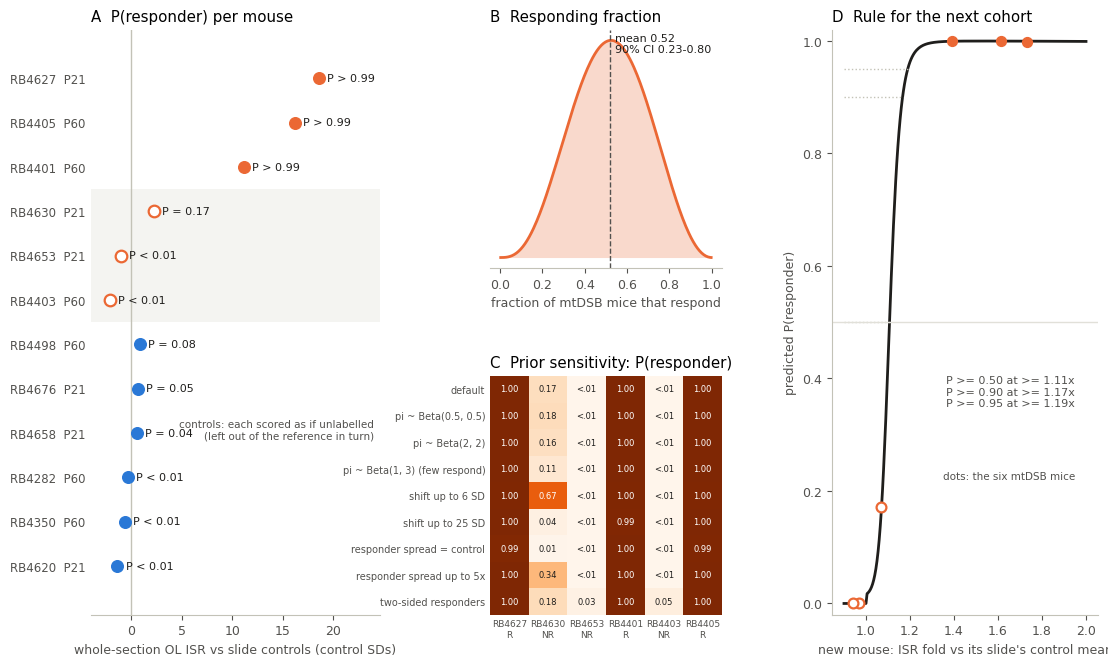

In [7]:
fig = plt.figure(figsize=(13, 7.6))
gsp = fig.add_gridspec(2, 3, width_ratios=[1.25, 1, 1.15], hspace=0.45, wspace=0.42)

# A: per-mouse shift and P
ax = fig.add_subplot(gsp[:, 0])
d = primary.assign(o=primary["hard call"].map({"control": 0, "non-responder": 1, "responder": 2})).sort_values(["o", "shift (control SDs)"])
yy = np.arange(len(d))
for y_, (sid, r) in zip(yy, d.iterrows()):
    g = r["hard call"]
    kw = dict(color=BLUE) if g == "control" else (dict(facecolor="white", edgecolor=ORANGE, linewidth=1.6) if g == "non-responder" else dict(color=ORANGE))
    ax.scatter(r["shift (control SDs)"], y_, s=70, zorder=3, **kw)
    pv = r["P(responder)"]
    ax.text(r["shift (control SDs)"] + 0.8, y_, "P > 0.99" if pv > 0.99 else ("P < 0.01" if pv < 0.01 else f"P = {pv:.2f}"),
            va="center", fontsize=8, color=INK)
ax.axvline(0, color=AXIS, lw=1); ax.set_xlim(-4, max(d["shift (control SDs)"]) + 6)
ax.set_yticks(yy); ax.set_yticklabels([f"{sid}  P{a}" for sid, a in zip(d.index, d.age)], fontsize=8.5)
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
for y0, y1 in ((-0.5, 5.5), (5.5, 8.5), (8.5, 11.5)):
    ax.axhspan(y0, y1, color=GRID if y0 == 5.5 else "white", alpha=0.35, lw=0, zorder=0)
ax.set_xlabel("whole-section OL ISR vs slide controls (control SDs)")
ax.set_title("A  P(responder) per mouse", loc="left")
ax.text(0.98, 0.30, "controls: each scored as if unlabelled\n(left out of the reference in turn)", transform=ax.transAxes,
        ha="right", fontsize=7.5, color=INK2)

# B: posterior of pi
ax = fig.add_subplot(gsp[0, 1])
ax.fill_between(res["pi_grid"], res["pi_density"], color=ORANGE, alpha=0.25, lw=0)
ax.plot(res["pi_grid"], res["pi_density"], color=ORANGE, lw=2)
ax.axvline(res["e_pi"], color=INK2, lw=1, ls="--")
ax.text(res["e_pi"] + 0.02, ax.get_ylim()[1] * 0.9, f"mean {res['e_pi']:.2f}\n90% CI {lo:.2f}-{hi:.2f}", fontsize=8, color=INK)
ax.set_xlabel("fraction of mtDSB mice that respond"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title("B  Responding fraction", loc="left")

# C: sensitivity
ax = fig.add_subplot(gsp[1, 1])
sv = sens[list(mt)].clip(1e-3, 1 - 1e-3)
im = ax.imshow(sv.to_numpy(), cmap="Oranges", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(mt))); ax.set_xticklabels([f"{m}\n{'R' if hard[m] == 'responder' else 'NR'}" for m in mt], fontsize=6.5)
ax.set_yticks(range(len(sv))); ax.set_yticklabels(sv.index, fontsize=7)
for i in range(sv.shape[0]):
    for j in range(sv.shape[1]):
        v = sens.iloc[i][mt[j]]
        ax.text(j, i, f"{v:.2f}" if v >= 0.005 else "<.01", ha="center", va="center", fontsize=6, color="white" if v > 0.6 else INK)
ax.set_title("C  Prior sensitivity: P(responder)", loc="left")
for s_ in ax.spines.values(): s_.set_visible(False)
ax.tick_params(length=0)

# D: next-cohort rule
ax = fig.add_subplot(gsp[:, 2])
ax.plot(fc, pp, color=INK, lw=2)
for q, v in thr.items():
    ax.plot([0.9, v], [q, q], color=AXIS, lw=1, ls=":")
ax.text(1.95, 0.35, "\n".join(f"P >= {q:.2f} at >= {v:.2f}x" for q, v in thr.items()), ha="right", fontsize=8, color=INK2)
ax.text(1.95, 0.22, "dots: the six mtDSB mice", ha="right", fontsize=7.5, color=INK2)
for sid, r in primary.iterrows():
    if r["hard call"] == "control": continue
    f_ = r["ISR fold vs slide controls"]
    kw = dict(color=ORANGE) if r["hard call"] == "responder" else dict(facecolor="white", edgecolor=ORANGE, linewidth=1.6)
    ax.scatter(min(f_, 2.0), r["P(responder)"], s=50, zorder=3, clip_on=False, **kw)
ax.set_xlabel("new mouse: ISR fold vs its slide's control mean"); ax.set_ylabel("predicted P(responder)")
ax.set_ylim(-0.02, 1.02); ax.axhline(0.5, color=GRID, lw=1)
ax.set_title("D  Rule for the next cohort", loc="left")
fig.savefig(FIG / "R1_responder_probability.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG / "R1_responder_probability.pdf", bbox_inches="tight")

## Conclusions

* **Three of six mtDSB mice almost certainly respond** (RB4627, RB4405, RB4401: P > 0.99, 11-19 control SDs above
  their slide's controls; unchanged under every prior tried). **Two almost certainly do not** (RB4653, RB4403: below
  their slide's control mean; P < 0.01, or 0.03-0.05 if responders may also lie below the controls).
* **RB4630 is the one open case: P = 0.17** (0.01-0.34 under reasonable priors). Its ISR is 1.07x its slide's
  controls (2.3 control SDs), above all three P21 controls but far below any responder. It could be a weak / late
  responder; it should not be called a clean non-responder, and it is the mouse to check first with the induction
  assay. (The 0.67 under "shift up to 6 SD" comes from a prior that cannot fit the observed responders, 11-19 SD.)
* **Null check passes**: no control, scored as if unlabelled, exceeds P = 0.08.
* **Responding fraction**: mean 0.52, 90% credible interval 0.23-0.80. Six mice cannot tell "half respond" from
  "a quarter" or "most".
* **The pseudobulk ISR score is the best per-mouse readout.** The per-OL ISR mean is noisier (a control reaches
  P = 0.93) and the condition classifier alone separates the mice poorly (control RB4658 P = 0.90). Adding the
  classifier to ISR changes nothing (RB4630 0.17 -> 0.06).
* **Operating characteristics** (simulated cohorts of this design): true responders get P > 0.9 every time;
  non-responders get P > 0.9 1% of the time and P < 0.1 87% of the time. The intermediate band is conservative:
  no simulated mouse with 0.1 < P < 0.9 was a responder.
* **Rule for the next cohort**: with three controls per slide, a mtDSB mouse whose whole-section OL ISR score is
  >= 1.17x its slide's control mean has P(responder) >= 0.9 (1.11x for 0.5, 1.19x for 0.95). Controls here vary by
  only ~3% (SD of log ISR 0.029), so this cut-off is well above control noise yet far below the responders seen
  (1.39-1.73x). Report the probability for every mouse rather than dropping "non-responders".